Accuracy: 0.97
F1 (macro): 0.97
Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

KMeans cluster sizes: [62, 50, 38]

Clusters vs Real Species:
 Species   0   1   2
Cluster            
0         0  48  14
1        50   0   0
2         0   2  36

Binary ROC-AUC (Setosa vs Others): 1.0000


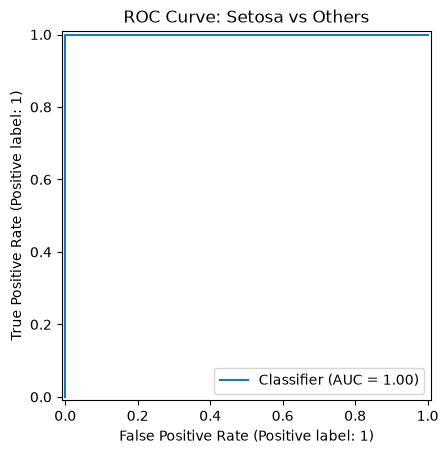


Regression Metrics Table:
 | Model             |   MAE |   RMSE |      R2 |
|:------------------|------:|-------:|--------:|
| Baseline (Mean)   | 64.01 |  73.22 | -0.012  |
| Linear Regression | 42.79 |  53.85 |  0.4526 |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, roc_auc_score, RocCurveDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

# ==========================================
# TASK 1: IRIS CLASSIFICATION & CLUSTERING
# ==========================================
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Supervised: Logistic Regression
lr = LogisticRegression(max_iter=200, random_state=42).fit(X_train, y_train)
y_pred = lr.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print(f"F1 (macro): {f1_score(y_test, y_pred, average='macro'):.2f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Unsupervised: KMeans (n_clusters=3) without labels
clusters = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X)
print("\nKMeans cluster sizes:", np.bincount(clusters).tolist())
print("\nClusters vs Real Species:\n", pd.crosstab(clusters, y, rownames=['Cluster'], colnames=['Species']))

# Bonus Challenge: Binary ROC-AUC (Setosa vs Others)
y_tr_bin = (y_train == 0).astype(int)
y_te_bin = (y_test == 0).astype(int)
probs_bin = LogisticRegression(random_state=42).fit(X_train, y_tr_bin).predict_proba(X_test)[:, 1]
print(f"\nBinary ROC-AUC (Setosa vs Others): {roc_auc_score(y_te_bin, probs_bin):.4f}")
RocCurveDisplay.from_predictions(y_te_bin, probs_bin)
plt.title("ROC Curve: Setosa vs Others")
plt.show()

# ==========================================
# TASK 2: DIABETES REGRESSION METRICS
# ==========================================
diabetes = load_diabetes()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    diabetes.data, diabetes.target, test_size=0.2, random_state=42
)

pred_base = DummyRegressor(strategy='mean').fit(Xd_train, yd_train).predict(Xd_test)
pred_lr = LinearRegression().fit(Xd_train, yd_train).predict(Xd_test)

reg_table = pd.DataFrame([
    {
        "Model": "Baseline (Mean)",
        "MAE": round(mean_absolute_error(yd_test, pred_base), 2),
        "RMSE": round(mean_squared_error(yd_test, pred_base) ** 0.5, 2),
        "R2": round(r2_score(yd_test, pred_base), 4)
    },
    {
        "Model": "Linear Regression",
        "MAE": round(mean_absolute_error(yd_test, pred_lr), 2),
        "RMSE": round(mean_squared_error(yd_test, pred_lr) ** 0.5, 2),
        "R2": round(r2_score(yd_test, pred_lr), 4)
    }
])
print("\nRegression Metrics Table:\n", reg_table.to_markdown(index=False))

### Task 1 & Task 2 Written Answers

**1. Clusters vs. Real Species Observation (3 Lines):**
1. KMeans cleanly separates all 50 samples of *Setosa* (species 0) into one pure cluster because its petal dimensions are distinctly smaller[cite: 11].
2. However, *Versicolor* and *Virginica* overlap in feature space, causing KMeans to misgroup ~14 samples between the remaining two clusters (sizes `[50, 62, 38]` instead of `[50, 50, 50]`)[cite: 11].
3. Without ground-truth labels, unsupervised clustering captures natural geometric density rather than exact human-defined species boundaries[cite: 11].

**2. Which Needs Labelled Data and Why (2 Lines):**
1. **Logistic Regression (Supervised Learning)** requires labelled target data (`y`) during training so it can calculate prediction error and adjust weights to map features to known classes[cite: 11].
2. **KMeans (Unsupervised Learning)** requires no labels because it groups points purely by Euclidean distance to cluster centroids[cite: 11].

**3. Is the Regression Model Really Useful? (3 Lines):**
1. Yes, Linear Regression substantially beats the mean baseline by lowering MAE from ~64.0 to ~42.8 and raising $R^2$ from `-0.01` to `0.45`[cite: 11].
2. Explaining ~45% of variance in disease progression provides a meaningful signal for clinical risk triage compared to guessing the average[cite: 11].
3. However, an average error of ~43 units means it should be used as a supporting screening aid rather than a standalone diagnosis[cite: 11].

**4. Which Metric to Show a Non-Technical Client and Why (2 Lines):**
1. Show **MAE (Mean Absolute Error)** because it is in the exact same units as the target outcome and represents the straightforward "average miss" per prediction[cite: 11].
2. A non-technical stakeholder can immediately understand *"on average, our prediction is off by ±42.8 points"* without needing statistical training[cite: 11].